In [35]:
import sys
import pandas as pd
import numpy as np
import seaborn as sns
from pathlib import Path
import matplotlib.pyplot as plt
import statsmodels.api as sm
from matplotlib.ticker import StrMethodFormatter
plt.style.use('dark_background')

In [36]:
cwd = Path.cwd()
project_root = cwd.parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
    print('Done!')

In [37]:
data_path = project_root / 'data' / 'processed' / 'demand_development.csv'
demand_data = pd.read_csv(data_path)

In [38]:
utc_columns = [
    'timestamp_utc',
    'timestamp_london',
    'interval_end_utc',
    'forecast_issue_utc',
    'forecast_cutoff_utc',
    'scheduled_kickoff_utc',
]

for column in utc_columns:
    demand_data[column] = pd.to_datetime(
        demand_data[column], utc=True
    )

In [39]:
demand_data['timestamp_london'] = demand_data['timestamp_utc'].dt.tz_convert('Europe/London')

In [40]:
demand_data['settlement_date'] = pd.to_datetime(
    demand_data['settlement_date']
)

In [41]:
train_set = demand_data.loc[demand_data['data_split'] == 'train'].copy()
train_set = train_set.sort_values(by='timestamp_utc')

In [42]:
train_set.head()

,timestamp_utc,interval_end_utc,timestamp_london,settlement_date,settlement_period,demand_mw,neso_day_ahead_forecast_mw,historic_nd_mw,historic_tsd_mw,forecast_issue_utc,...,match_id,opponent,scheduled_kickoff_utc,match_stage,event_role,temperature_london_c_retrospective,temperature_manchester_c_retrospective,temperature_birmingham_c_retrospective,temperature_proxy_c_retrospective,weather_ex_ante_eligible
0,2023-01-01 00:00:00+00:00,2023-01-01 00:30:00+00:00,2023-01-01 00:00:00+00:00,2023-01-01,1,20967,20320,21043,24680,2022-12-31 08:45:00+00:00,...,NaN,NaN,NaT,NaN,NaN,11.60,9.00,9.1,9.900000,False
1,2023-01-01 00:30:00+00:00,2023-01-01 01:00:00+00:00,2023-01-01 00:30:00+00:00,2023-01-01,2,21699,20680,21756,25289,2022-12-31 08:45:00+00:00,...,NaN,NaN,NaT,NaN,NaN,11.55,8.85,9.0,9.800000,False
2,2023-01-01 01:00:00+00:00,2023-01-01 01:30:00+00:00,2023-01-01 01:00:00+00:00,2023-01-01,3,21185,20498,21348,25269,2022-12-31 08:45:00+00:00,...,NaN,NaN,NaT,NaN,NaN,11.50,8.70,8.9,9.700000,False
3,2023-01-01 01:30:00+00:00,2023-01-01 02:00:00+00:00,2023-01-01 01:30:00+00:00,2023-01-01,4,20442,19955,20586,24574,2022-12-31 08:45:00+00:00,...,NaN,NaN,NaT,NaN,NaN,11.35,8.50,8.7,9.516667,False
4,2023-01-01 02:00:00+00:00,2023-01-01 02:30:00+00:00,2023-01-01 02:00:00+00:00,2023-01-01,5,19633,19512,19781,24135,2022-12-31 08:45:00+00:00,...,NaN,NaN,NaT,NaN,NaN,11.20,8.30,8.5,9.333333,False


In [43]:
demand_series = train_set['demand_mw']
demand_series.index = train_set['timestamp_utc']
demand_series.head()

timestamp_utc
2023-01-01 00:00:00+00:00    20967
2023-01-01 00:30:00+00:00    21699
2023-01-01 01:00:00+00:00    21185
2023-01-01 01:30:00+00:00    20442
2023-01-01 02:00:00+00:00    19633
Name: demand_mw, dtype: int64

In [44]:
demand_series.info()

<class 'pandas.Series'>
DatetimeIndex: 20400 entries, 2023-01-01 00:00:00+00:00 to 2024-02-29 23:30:00+00:00
Series name: demand_mw
Non-Null Count  Dtype
--------------  -----
20400 non-null  int64
dtypes: int64(1)
memory usage: 318.8 KB


In [45]:
demand_series.index.diff().dropna().value_counts()

timestamp_utc
0 days 00:30:00    20399
Name: count, dtype: int64

Change from 30 minutes earlier

In [46]:
first_diff = demand_series.subtract(demand_series.shift(1))
first_diff.head()

timestamp_utc
2023-01-01 00:00:00+00:00      NaN
2023-01-01 00:30:00+00:00    732.0
2023-01-01 01:00:00+00:00   -514.0
2023-01-01 01:30:00+00:00   -743.0
2023-01-01 02:00:00+00:00   -809.0
Name: demand_mw, dtype: float64

In [47]:
print(f'Missing values in first diff: {len(first_diff[first_diff.isna()])}')

Missing values in first diff: 1


Change from 24 elapsed hours earlier

In [48]:
daily_diff = demand_series.subtract(demand_series.shift(48))
daily_diff.tail()

timestamp_utc
2024-02-29 21:30:00+00:00    2462.0
2024-02-29 22:00:00+00:00    2710.0
2024-02-29 22:30:00+00:00    2740.0
2024-02-29 23:00:00+00:00    3059.0
2024-02-29 23:30:00+00:00    3205.0
Name: demand_mw, dtype: float64

In [49]:
print(f'Missing values in daily diff: {len(daily_diff[daily_diff.isna()])}')

Missing values in daily diff: 48


Change from 168 elapsed hours earlier

In [50]:
weekly_diff = demand_series.subtract(demand_series.shift(336))
weekly_diff.tail()

timestamp_utc
2024-02-29 21:30:00+00:00    772.0
2024-02-29 22:00:00+00:00    701.0
2024-02-29 22:30:00+00:00    416.0
2024-02-29 23:00:00+00:00    577.0
2024-02-29 23:30:00+00:00    523.0
Name: demand_mw, dtype: float64

In [51]:
print(f'Missing values in weekly diff: {len(weekly_diff[weekly_diff.isna()])}')

Missing values in weekly diff: 336


verifying the transformations

In [52]:
summary = []
for s in [first_diff, daily_diff, weekly_diff]:
    report = {
        'Number of observations': len(s),
        'Number of missing values': len(s[s.isna()]),
        'Mean': s.mean(),
        'Standard deviation': s.std(),
        'Minimum': s.min(),
        'Maximum': s.max()
    }
    summary.append(report)
    
summary_df = pd.DataFrame(summary)

In [53]:
summary_df.loc[len(summary_df)] = {
        'Number of observations': len(demand_series),
        'Number of missing values': len(demand_series[demand_series.isna()]),
        'Mean': demand_series.mean(),
        'Standard deviation': demand_series.std(),
        'Minimum': demand_series.min(),
        'Maximum': demand_series.max()
    }

In [54]:
summary_df = summary_df.loc[[3, 0, 1, 2]]

In [55]:
summary_df.head()

,Number of observations,Number of missing values,Mean,Standard deviation,Minimum,Maximum
3,20400,0,26663.920588,6213.309192,13598.0,45096.0
0,20400,1,0.233688,911.994437,-2586.0,3754.0
1,20400,48,15.388070,2573.152260,-11077.0,13271.0
2,20400,336,52.991079,2879.511270,-13347.0,17387.0


In [56]:
summary_df.index = pd.Series(['Raw demand', 'First difference', 'Daily difference', 'Weekly difference'])

In [57]:
summary_df.head()

,Number of observations,Number of missing values,Mean,Standard deviation,Minimum,Maximum
Raw demand,20400,0,26663.920588,6213.309192,13598.0,45096.0
First difference,20400,1,0.233688,911.994437,-2586.0,3754.0
Daily difference,20400,48,15.388070,2573.152260,-11077.0,13271.0
Weekly difference,20400,336,52.991079,2879.511270,-13347.0,17387.0


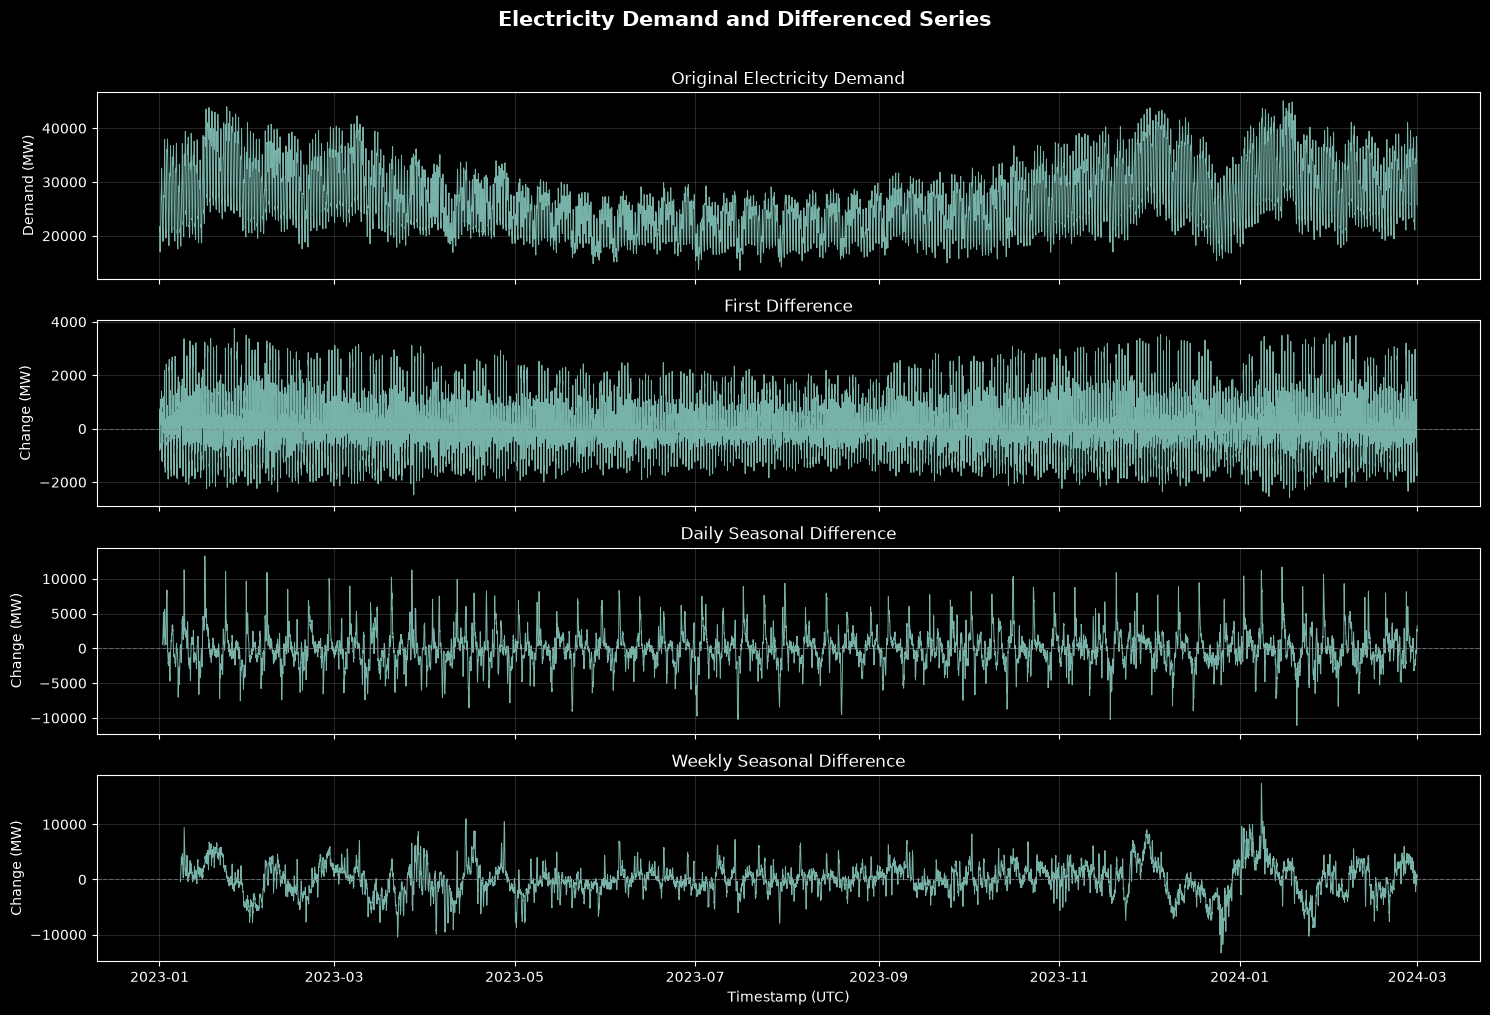

In [62]:
fig, axes = plt.subplots(
    4, 1,
    figsize=(15, 10),
    sharex=True
)

series = [
    (demand_series, 'Original Electricity Demand'),
    (first_diff, 'First Difference'),
    (daily_diff, 'Daily Seasonal Difference'),
    (weekly_diff, 'Weekly Seasonal Difference')
]

for i, (ax, (s, title)) in enumerate(zip(axes.flat, series)):
    ax.plot(
        s.index,
        s.values,
        linewidth=0.7,
        alpha=0.85
    )

    ax.set(
        title=title,
        ylabel='Demand (MW)' if i == 0 else 'Change (MW)'
    )

    if i > 0:
        ax.axhline(
            0,
            color='gray',
            linestyle='--',
            linewidth=0.8,
            alpha=0.7
        )

    ax.grid(alpha=0.15)

axes[-1].set_xlabel('Timestamp (UTC)')

fig.suptitle(
    'Electricity Demand and Differenced Series',
    fontsize=15,
    fontweight='bold',
    y=1.01
)

plt.tight_layout()
plt.show()